In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [44]:
dir = '/home/hedi/HSCNG/SBI/leaveout_DI/'

pull_rms = []
S8_pred_all = []
S8_err_all = []
pull_mean = []
bias_mean = []
bias_rms = []
coverage_all = []

for i in range(50):
    res = np.load(f'{dir}{i}_results.npz', allow_pickle=True)
    bias_test = res['bias_test']
    pull_test = res['pull_test']
    coverage = res['coverage']
    S8_pred = res['constrained_S8'][:,1]
    S8_err = np.c_[
        res['constrained_S8'][:,1] - res['constrained_S8'][:,0],
        res['constrained_S8'][:,2] - res['constrained_S8'][:,1]
    ]

    S8_pred_all.append(S8_pred)
    S8_err_all.append(S8_err)

    S8_true = res['true_S8'][0]
    pull_rms.append(np.sqrt(np.mean(pull_test**2)))
    pull_mean.append(np.mean(pull_test))
    bias_mean.append(np.mean(bias_test))
    bias_rms.append(np.sqrt(np.mean(bias_test**2)))
    coverage_all.append(coverage.mean(axis=1))


In [45]:
S8_pred_all = np.concatenate(S8_pred_all, axis=0)
S8_err_all = np.concatenate(S8_err_all, axis=0)

In [46]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)
Om = cosmo_pars[:,1]
S8 = cosmo_pars[:,3]

In [47]:
S8_err_all

array([[0.01713018, 0.01813241],
       [0.0189713 , 0.01679678],
       [0.02142441, 0.020596  ],
       ...,
       [0.01017175, 0.01181194],
       [0.01116406, 0.011232  ],
       [0.01261111, 0.0120882 ]], shape=(2500, 2))

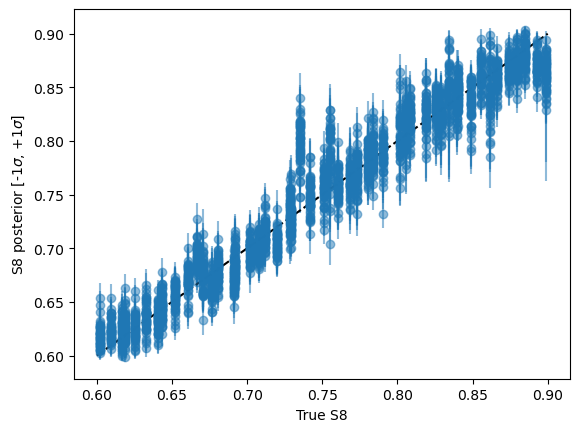

In [48]:
plt.errorbar(
    np.repeat(S8, 50),
    S8_pred_all,
    S8_err_all.T,
    fmt='o',
    alpha=0.5,
)

plt.plot([0.6, 0.9], [0.6, 0.9], 'k--')
plt.xlabel('True S8')
plt.ylabel('S8 posterior [-1$\sigma$, +1$\sigma$]')
plt.show()

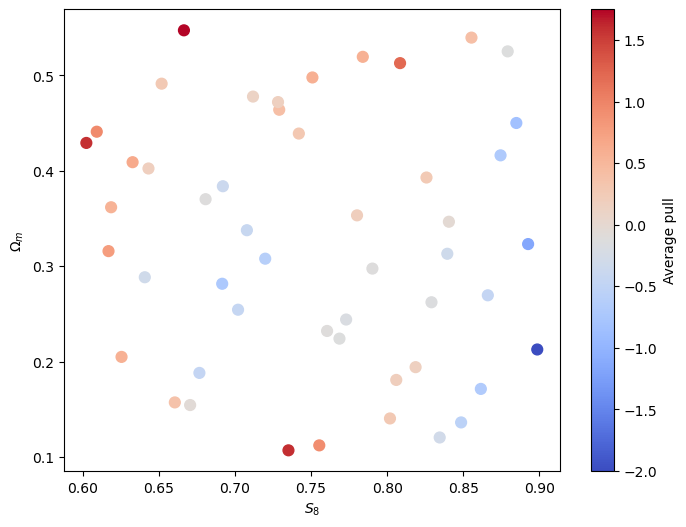

In [14]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)

scatter = ax.scatter(
    S8,
    Om,
    c=pull_mean,
    cmap="coolwarm",
    s=60,
)

ax.set_xlabel(r"$S_8$")
ax.set_ylabel(r"$\Omega_m$")
# ax.set_zlabel("Average bias")
fig.colorbar(scatter, ax=ax, label="Average pull")

plt.show()

In [55]:
res = np.load(f'{dir}/5_results.npz', allow_pickle=True)

In [56]:
bias_test = res['bias_test']
pull_test = res['pull_test']
coverage = res['coverage']

In [57]:
S8_pred = res['constrained_S8'][:,1]

S8_err = np.c_[
    res['constrained_S8'][:,1] - res['constrained_S8'][:,0],
    res['constrained_S8'][:,2] - res['constrained_S8'][:,1]
]

S8_true = res['true_S8'][0]

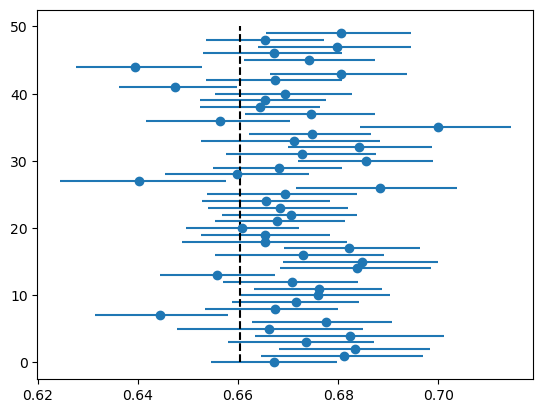

In [58]:
plt.errorbar(
    S8_pred, np.arange(len(S8_pred)), xerr=S8_err.T, fmt='o', label='Predicted S8'
)
plt.vlines(S8_true, 0, 50, linestyle='--', color='k', label='True S8')

In [60]:
xx = np.linspace(0, 1, 30)

In [61]:
index = []
for i in range(len(coverage_all)):
    coverage = coverage_all[i]
    if (np.abs(coverage - xx) > 0.3).any():
        index.append(i)

/var/tmp/pbs.604910.idark/ipykernel_267320/3300398644.py:12: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


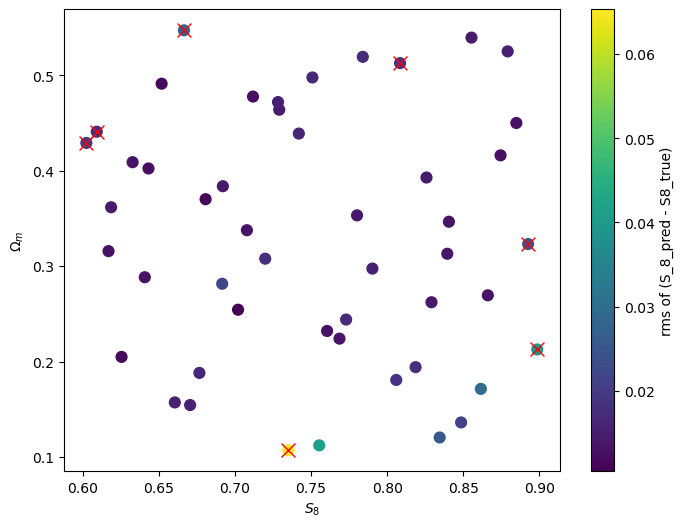

In [62]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)

scatter = ax.scatter(
    S8,
    Om,
    c=bias_rms,
    cmap="viridis",
    s=60,
)

ax.scatter(
    S8[index],
    Om[index],
    marker='x',
    s=100,
    c='red',
    edgecolors='black',
    linewidth=1,
    
)


ax.set_xlabel(r"$S_8$")
ax.set_ylabel(r"$\Omega_m$")
# ax.set_zlabel("Average bias")
fig.colorbar(scatter, ax=ax, label="rms of (S_8_pred - S8_true)")

plt.show()

## coverage

the coverage looks like this: if you choose a percentile e.g. x = 30%, then trying to find the central area (50 - 15, 50 + 15)% of the distribution, and find the percentile where the 

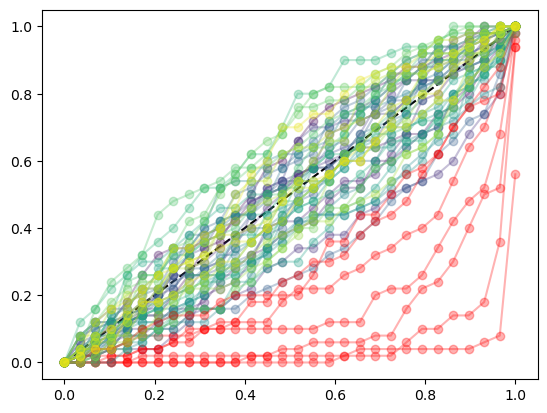

In [63]:
plt.plot([0, 1], [0, 1], 'k--', label='Ideal coverage')
cmap = plt.get_cmap('viridis')

for i in range(50):
    if i in index:
        plt.plot(xx, coverage_all[i], 'o-', color='red', alpha=0.3)

    else:
        plt.plot(xx, coverage_all[i], 'o-', color=cmap(i/50), alpha=0.3)
# plt.plot(xx, xx - 0.3, 'r--', label='20% lower bound')
# plt.plot(xx, xx + 0.3, 'r--', label='20% upper bound')

In [64]:
field = 'XMM'
tomo = 1

In [65]:
from astropy.io import fits

In [66]:
dats = [
    fits.getdata(f'/home/hedi/HSCNG/SBI/glass_hsc_lf/output/cosmo_fiducial/realization_0000/cutouts/kappa_glass_{field}_z{tomo}.fits', i)
    for i in range(1, 4)
]
mask_glass = (dats[1] > 0)
kappa_glass = dats[0]

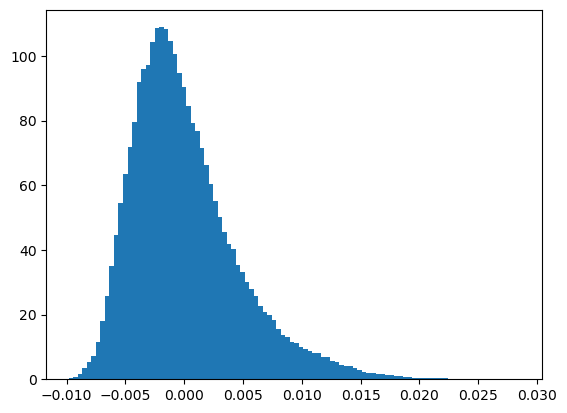

In [67]:
plt.hist(kappa_glass[mask_glass].flatten(), bins=100, density=True)
plt.show()

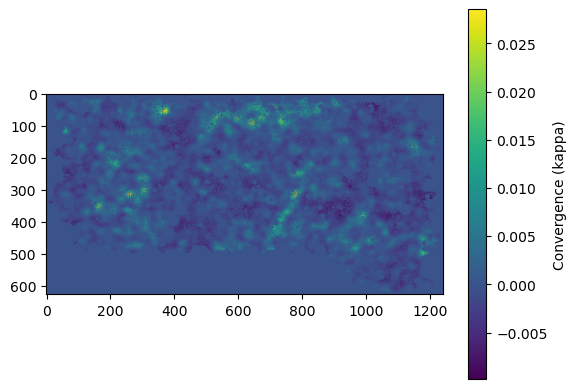

In [93]:
plt.imshow(kappa_glass, cmap='viridis')
plt.colorbar(label='Convergence (kappa)')

In [14]:
kappa = fits.getdata(
    '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/cosmo_varied/model{model_number}/E_{field}smoothed_z{tomo}_{realization}.fits'.format(model_number=1, field=field, tomo=tomo, realization=0),
    0
)
mask = fits.getdata(
    '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/cosmo_varied/model{model_number}/mask_{field}_z{tomo}.fits'.format(model_number=1, field=field, tomo=tomo),
    0
)

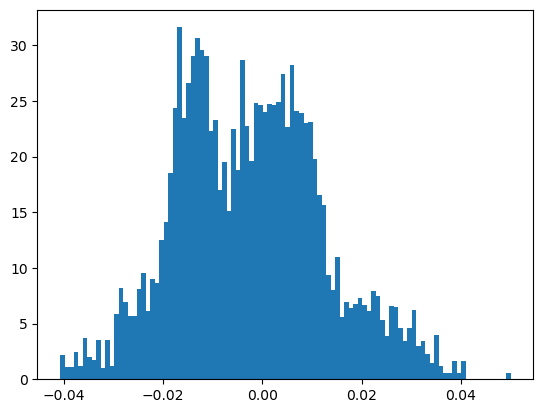

In [15]:
plt.hist(kappa[mask].flatten(), bins=100, density=True)
plt.show()

In [92]:
plt.imshow(kappa * mask, cmap='viridis')
plt.colorbar(label='Convergence (kappa)')

NameError: name 'kappa' is not defined

In [85]:
from astropy.wcs import WCS
def load_map_info(file):
    with fits.open(file) as map_fits:
        map_info = {}

        names = [
            'G1',
            'G2',
            'KAPPA',
            'KAPPA_I',
            'WEIGHT_MASK',
            'NMAP'
        ]

        keys = [
            'g1',
            'g2',
            'kappa',
            'kappa_i',
            'weight_mask',
            'nmap'
        ]

        for name, key in zip(names, keys):
            map_info[key] = map_fits[name].data

        map_info['wcs'] = WCS(map_fits[0].header)

    return map_info


In [18]:
res_di = load_map_info(
    '/home/hedi/HSCNG/maps/mock/node00_a/cone1/kappa_map_mock_{field}_z{tomo}_smooth g-inpainting-KSI-masking.fits'.format(field=field, tomo=tomo)
)

In [80]:
import sys
sys.path.append('/home/hedi/HSCNG/')
from hsc_y3_utils import map_utils, stats_code

pixscale_arcmin = 0.5
smoothing_kernel_size = 5.4  # arcmin
smoothing_pix = smoothing_kernel_size / pixscale_arcmin

flatobj = map_utils.FlatClass(
        res_di['wcs'],
        res_di['kappa'].shape[1],
        res_di['kappa'].shape[0]
    )
kappa_smoothed = flatobj.smooth_G(
    res_di['kappa'],
    smoothing_pix
)

NameError: name 'res_di' is not defined

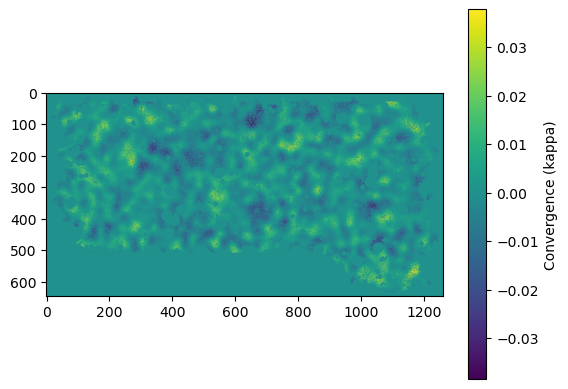

In [20]:
plt.imshow(kappa_smoothed * (res_di['weight_mask'] > 0))
plt.colorbar(label='Convergence (kappa)')

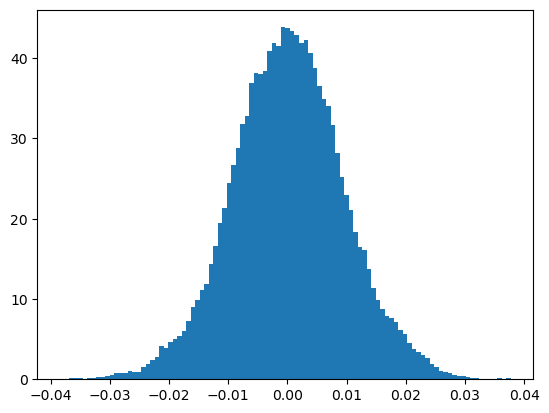

In [21]:
plt.hist(kappa_smoothed[res_di['weight_mask'] > 0], bins=100, density=True)
plt.show()

In [69]:
f = fits.open('/home/hedi/HSCNG/maps/random_rotations/kappa_random_rotation_{field}_z{tomo}_r0000.fits'.format(field=field, tomo=tomo))

In [70]:
for i in range(1, len(f)):
    print(f[i].header['EXTNAME'])
    # if f[i].header['EXTNAME'] == 'KAPPA_SIGNAL':
    #     KAPPA_SIGNAL = f[i].data

G1_NOISE
G2_NOISE
G1_NOISE_PROCESSED
G2_NOISE_PROCESSED
KAPPA_NOISE
KAPPA_NOISE_I
WEIGHT_MASK
NMAP


In [71]:
kappa_noise = f['KAPPA_NOISE'].data
kappa_noise_i = f['KAPPA_NOISE_I'].data
weights = f['WEIGHT_MASK'].data

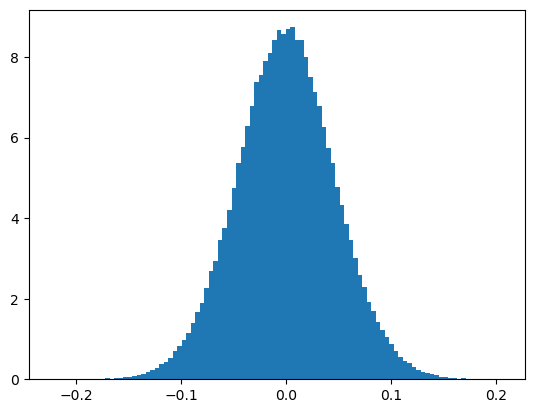

In [81]:
plt.hist(kappa_noise[weights > 0], bins=100, density=True)
plt.show()

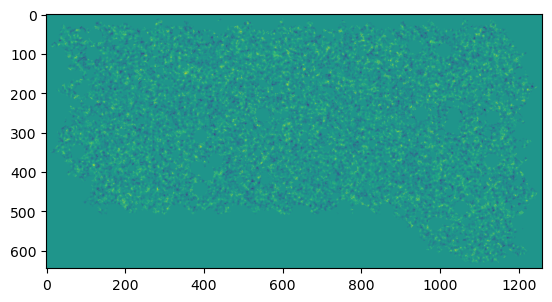

In [77]:
plt.imshow(kappa_noise * (weights > 0))

In [86]:
wcs = WCS(f[0].header)

In [87]:
flatobj = map_utils.FlatClass(
        wcs,
        kappa_noise.shape[1],
        kappa_noise.shape[0]
    )
kappa_smoothed = flatobj.smooth_G(
    kappa_noise,
    smoothing_pix
)

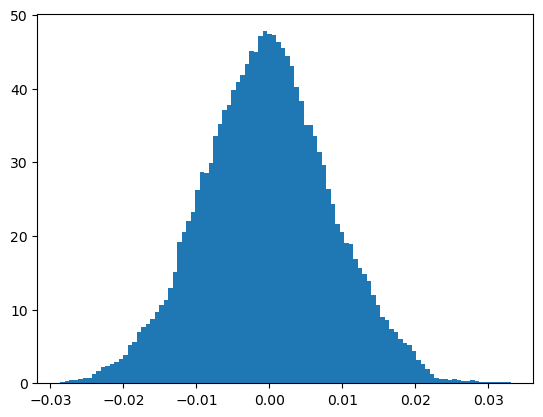

In [88]:
plt.hist(kappa_smoothed[weights > 0], bins=100, density=True)
plt.show()

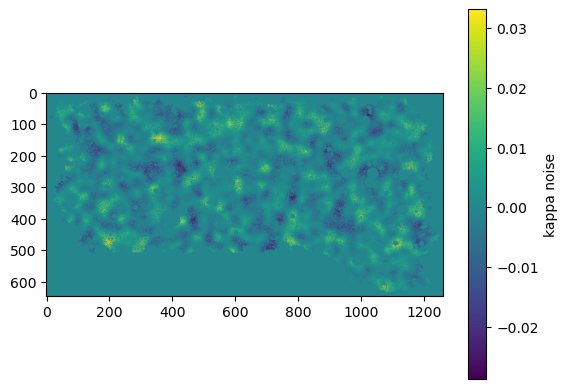

In [91]:
plt.imshow(kappa_smoothed * (weights > 0))
plt.colorbar(label='kappa noise')